# Chapitre 9 - Lab : verrou Redis, pause de processus et jetons de clôture

Le cours 4 a simulé le scénario le plus célèbre du chapitre : un client obtient un bail,
se fige, son bail expire, un autre client le prend, et le premier se réveille pour écrire
comme si de rien n'était. Ce lab le reproduit avec de **vrais** composants : un verrou à
bail dans Redis (`SET ... NX PX`), un stockage (un second Redis) et deux clients qui
tournent dans des conteneurs. Pour figer un client, on utilise `docker pause`, qui gèle
tous ses processus (comme une longue pause du ramasse-miettes ou une VM suspendue).
Puis on corrige avec des **jetons de clôture** vérifiés par le stockage. Sections du livre :
*Process Pauses*, *Distributed Locks and Leases*, *Fencing off zombies and delayed requests*.

**Plan.**

0. Démarrer les services et vérifier la connexion.
1. Un bail dans Redis : `SET NX PX`.
2. Le zombie : `docker pause` pendant que le bail expire.
3. La parade : des jetons de clôture vérifiés par le stockage.
4. Ce que le processus figé a vu.
5. Pour aller plus loin, et arrêt des services.

## 0. Démarrer les services et vérifier la connexion

Le fichier [`docker/distsys/compose.yml`](../../docker/distsys/compose.yml) définit quatre
conteneurs : `lock` (Redis qui sert de service de verrous, port hôte 10901), `storage`
(Redis qui joue le service de stockage, port 10902), et `worker1`, `worker2`, deux
clients qui exécutent le script [`docker/distsys/worker.sh`](../../docker/distsys/worker.sh)
avec `redis-cli`. Depuis la racine du dépôt :

```bash
docker compose -f docker/distsys/compose.yml -p ddia_distsys up -d     # démarrer
docker compose -f docker/distsys/compose.yml -p ddia_distsys down -v   # arrêter et nettoyer
```

Le script d'un client fait, dans l'ordre : obtenir le bail ; « préparer » l'écriture
(`TRAVAIL` secondes) ; **vérifier** que le bail lui appartient toujours ; travailler encore
une seconde ; **écrire** dans le stockage. C'est la boucle naïve du livre : vérifier, puis
agir. Chaque étape est journalisée dans une liste `evenements` du stockage, avec un
horodatage lu dans `/proc/uptime`, une horloge **monotone** commune à tous les
conteneurs puisqu'ils partagent le noyau de la machine hôte.

In [1]:
import subprocess
import time

import matplotlib.pyplot as plt
import pandas as pd
import redis

from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16

PROJET = "ddia_distsys"
W1, W2 = f"{PROJET}-worker1-1", f"{PROJET}-worker2-1"
verrous = redis.Redis(host="localhost", port=10901, decode_responses=True)
stockage = redis.Redis(host="localhost", port=10902, decode_responses=True)
try:
    print("service de verrous :", verrous.ping(), "; stockage :", stockage.ping(), "; Redis", verrous.info()["redis_version"])
    etat = subprocess.run(["docker", "inspect", "-f", "{{.State.Status}}", W1, W2], capture_output=True, text=True, check=True)
    print("clients :", etat.stdout.split())
except Exception as exc:                                   # noqa: BLE001
    raise SystemExit("Services absents : lancez d'abord docker compose ... up -d (voir ci-dessus).") from exc


def maintenant_ms():
    """Horloge monotone de l'hôte, la même que celle des conteneurs (/proc/uptime)."""
    with open("/proc/uptime") as f:
        return int(float(f.read().split()[0]) * 1000)


def docker(*args):
    subprocess.run(["docker", *args], check=True, capture_output=True)

service de verrous : True ; stockage : True ; Redis 7.4.11
clients : ['running', 'running']


## 1. Un bail dans Redis : `SET NX PX`

Redis fournit un verrou à bail en une commande atomique : `SET verrou <propriétaire> NX PX
<durée>` ne réussit que si la clé n'existe pas (`NX`) et la fait expirer après la durée
donnée en millisecondes (`PX`). C'est le serveur qui fait expirer le bail, avec **sa**
notion du temps. Observons un bail de 2 s : on interroge sa durée restante (`PTTL`) toutes
les 100 ms, et un second client tente de le prendre en même temps.

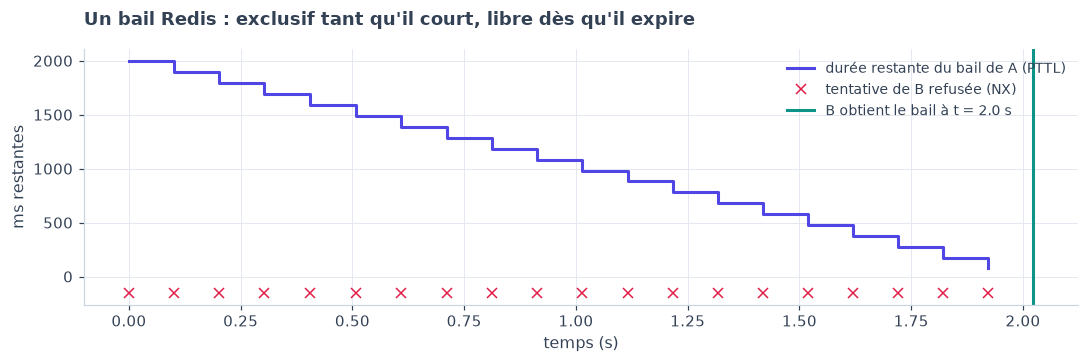

,t,ttl,détenteur,B_réussit
18,1.820815,179,client A,False
19,1.921277,78,client A,False
20,2.021980,1998,client B,True


In [2]:
verrous.flushall()
t0 = time.monotonic()
assert verrous.set("verrou", "client A", nx=True, px=2000)
mesures = []
while time.monotonic() - t0 < 2.6:
    t = time.monotonic() - t0
    prise_b = bool(verrous.set("verrou", "client B", nx=True, px=2000))
    mesures.append(dict(t=t, ttl=max(verrous.pttl("verrou"), 0), détenteur=verrous.get("verrou"), B_réussit=prise_b))
    if prise_b:
        break
    time.sleep(0.1)
M = pd.DataFrame(mesures)
fig, ax = plt.subplots(figsize=(10, 3.4))
a = M[M.détenteur == "client A"]
ax.step(a.t, a.ttl, where="post", color=INDIGO, label="durée restante du bail de A (PTTL)")
ok = M[M.B_réussit]
for _, r in M[~M.B_réussit].iterrows():
    ax.plot(r.t, -150, "x", color=ROSE, ms=6)
ax.plot([], [], "x", color=ROSE, label="tentative de B refusée (NX)")
if len(ok):
    ax.axvline(ok.t.iloc[0], color=TEAL, lw=2, label=f"B obtient le bail à t = {ok.t.iloc[0]:.1f} s")
ax.set_xlabel("temps (s)"); ax.set_ylabel("ms restantes")
ax.set_title("Un bail Redis : exclusif tant qu'il court, libre dès qu'il expire")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
M.tail(3)

Toutes les tentatives de B échouent tant que le bail de A court ; dès qu'il expire (le
serveur supprime la clé), B l'obtient. Le serveur ne sait **rien** de l'état de A : il a
peut-être planté, ou il est simplement figé. C'est exactement ce que l'on veut quand A est
mort, et exactement le danger quand A n'est qu'en pause.

> **À retenir.** `SET NX PX` donne un bail exclusif dont l'expiration est décidée par le
> serveur, sans aucune information sur l'état réel du détenteur.

## 2. Le zombie : `docker pause` pendant que le bail expire

Scénario (bail de 3 s) :

1. à $t = 0$, `worker1` obtient le bail, prépare pendant 1 s, vérifie son bail (il lui
   reste 2 s, tout va bien), puis entame sa dernière seconde de travail ;
2. à $t = 1{,}5$ s, on le **gèle** avec `docker pause` ;
3. à $t = 3$ s, le bail expire côté serveur ; à $t = 4$ s, `worker2` obtient le bail,
   vérifie et écrit ;
4. à $t = 6{,}5$ s, on **dégèle** `worker1` (`docker unpause`) : il reprend là où il en
   était, c'est-à-dire juste avant d'écrire.

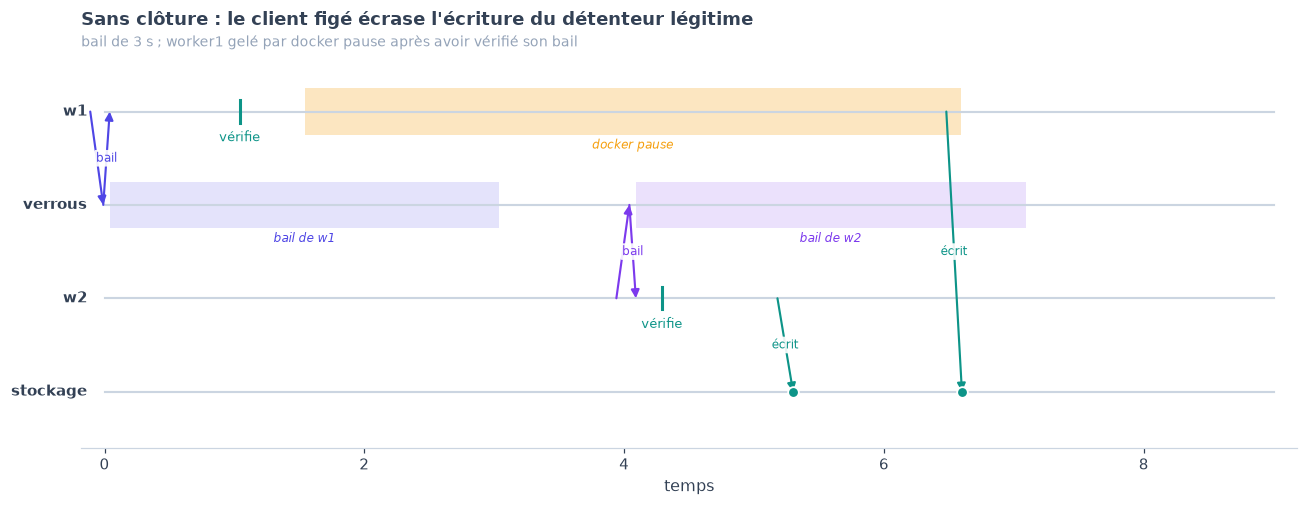

contenu final du fichier : 'contenu écrit par w1'


,t,client,événement,valeur
0,0.04,w1,verrou_obtenu,1
1,1.04,w1,bail_verifie,
2,4.09,w2,verrou_obtenu,1
3,4.29,w2,bail_verifie,
4,5.30,w2,ecriture_acceptee,1000
5,6.60,w1,ecriture_acceptee,5550


In [3]:
def scenario(mode):
    """Rejoue le scénario du zombie ; renvoie (événements, instants de pause, contenu final)."""
    verrous.flushall(); stockage.flushall()
    t0 = maintenant_ms()
    docker("exec", "-d", W1, "sh", "/worker.sh", "w1", mode, "3000", "1")
    time.sleep(1.5)
    t_pause = maintenant_ms(); docker("pause", W1)
    time.sleep(2.5)
    docker("exec", "-d", W2, "sh", "/worker.sh", "w2", mode, "3000", "0.2")
    time.sleep(2.5)
    t_reprise = maintenant_ms(); docker("unpause", W1)
    time.sleep(2.0)
    ev = []
    for ligne in stockage.lrange("evenements", 0, -1):
        t, qui, quoi, *reste = ligne.split()
        ev.append(dict(t=(int(t) - t0) / 1000, client=qui, événement=quoi, valeur=reste[0] if reste else ""))
    return pd.DataFrame(ev), ((t_pause - t0) / 1000, (t_reprise - t0) / 1000), stockage.get("fichier")


def dessine(ev, pause, titre, sous_titre):
    st = SpaceTime(["w1", "verrous", "w2", "stockage"], t_max=9, width=12, title=titre, subtitle=sous_titre)
    st.span("w1", pause[0], pause[1], "docker pause", color=AMBER)
    for _, r in ev.iterrows():
        c = INDIGO if r.client == "w1" else VIOLET
        if r.événement == "verrou_obtenu":
            st.msg(r.client, r.t - 0.15, "verrous", r.t - 0.05, "", color=c)
            st.msg("verrous", r.t - 0.05, r.client, r.t, "bail" + (f" {r.valeur}" if r.valeur != "1" or "jetons" in titre else ""), color=c)
            st.span("verrous", r.t, r.t + 3.0, f"bail de {r.client}", color=c, alpha=0.15)
        elif r.événement == "bail_verifie":
            st.event(r.client, r.t, "vérifie", kind="tick", color=TEAL)
        elif r.événement.startswith("ecriture"):
            ok = r.événement == "ecriture_acceptee"
            st.msg(r.client, r.t - 0.12, "stockage", r.t, "écrit" if ok else "refusée", color=TEAL if ok else ROSE)
            st.event("stockage", r.t, "", kind="point" if ok else "crash", color=TEAL if ok else ROSE)
    st.show()


ev_naif, pause_naif, fichier_naif = scenario("naif")
dessine(ev_naif, pause_naif, "Sans clôture : le client figé écrase l'écriture du détenteur légitime",
        "bail de 3 s ; worker1 gelé par docker pause après avoir vérifié son bail")
print("contenu final du fichier :", repr(fichier_naif))
ev_naif

Le journal raconte l'histoire du livre. `worker1` a obtenu le bail, l'a vérifié, puis a été
gelé. Le bail a expiré, `worker2` l'a obtenu et a écrit. Au dégel, `worker1` a écrit
**à son tour**, sans revérifier : le fichier contient maintenant le contenu du zombie,
et le travail du détenteur légitime est perdu. Le stockage n'a aucun moyen de savoir que
cette écriture vient d'un bail périmé.

## 3. La parade : des jetons de clôture vérifiés par le stockage

En mode `jetons`, le service de verrous accorde le bail **et** incrémente un compteur dans
la même opération atomique (un petit script Lua exécuté par Redis) : le client reçoit un
jeton croissant. Le stockage, lui, n'accepte une écriture que si son jeton est au moins
égal au plus grand jeton déjà vu (un autre script Lua, atomique côté stockage) :

```lua
-- service de verrous : bail et jeton en une seule opération
if redis.call('SET', KEYS[1], ARGV[1], 'NX', 'PX', ARGV[2]) then
  return redis.call('INCR', KEYS[2])
else return 0 end
-- stockage : refuser un jeton périmé
local m = tonumber(redis.call('GET', KEYS[1]) or '0')
if tonumber(ARGV[1]) < m then return 0 end
redis.call('SET', KEYS[1], ARGV[1]); redis.call('SET', KEYS[2], ARGV[2]); return 1
```

Rejouons exactement le même scénario.

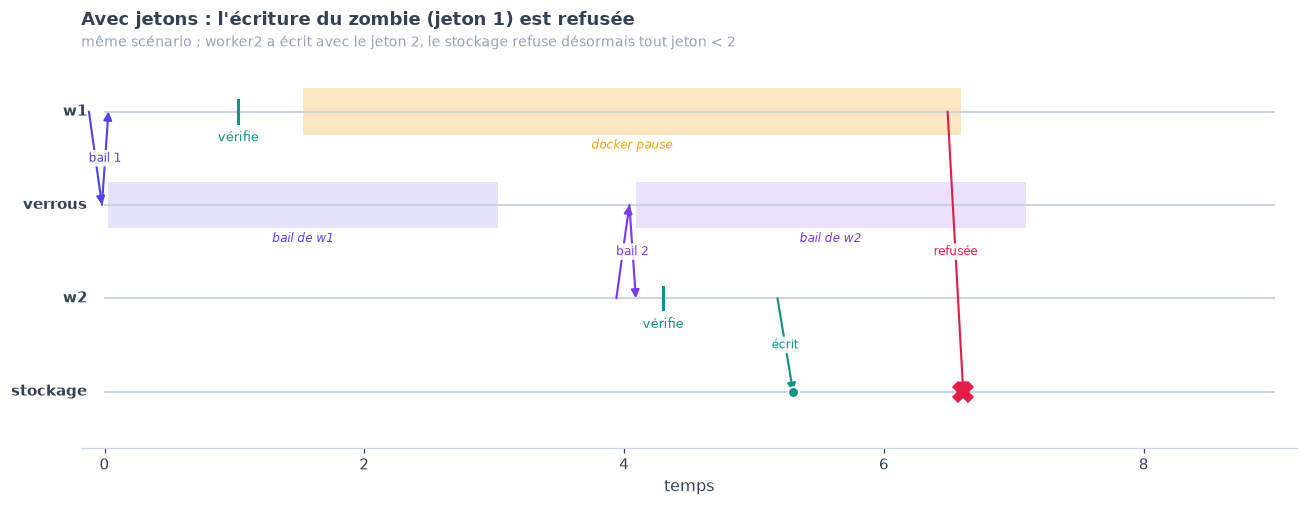

contenu final du fichier : 'contenu écrit par w2 (jeton 2)'


,t,client,événement,valeur
0,0.03,w1,verrou_obtenu,1
1,1.03,w1,bail_verifie,
2,4.09,w2,verrou_obtenu,2
3,4.30,w2,bail_verifie,
4,5.30,w2,ecriture_acceptee,1000
5,6.61,w1,ecriture_refusee,5570


In [4]:
ev_jet, pause_jet, fichier_jet = scenario("jetons")
dessine(ev_jet, pause_jet, "Avec jetons : l'écriture du zombie (jeton 1) est refusée",
        "même scénario ; worker2 a écrit avec le jeton 2, le stockage refuse désormais tout jeton < 2")
print("contenu final du fichier :", repr(fichier_jet))
ev_jet

Cette fois, `worker2` a reçu le jeton 2 et l'a présenté au stockage, qui retient « plus
grand jeton vu = 2 ». Au dégel, `worker1` présente le jeton 1 : écriture **refusée**, et
le fichier garde le contenu du détenteur légitime. Le client figé apprend, à ce
moment-là seulement, qu'il a perdu son bail. Remarquez que la protection est **dans le
stockage** : aucun changement chez le client ne pouvait l'empêcher d'être un zombie.

In [5]:
bilan = pd.DataFrame({
    "sans clôture": {"écriture de worker2": "acceptée", "écriture de worker1 (zombie)":
                     ev_naif[(ev_naif.client == "w1") & ev_naif.événement.str.startswith("ecriture")].événement.iloc[0].split("_")[1].replace("ee", "ée"),
                     "contenu final": fichier_naif},
    "avec jetons": {"écriture de worker2": "acceptée", "écriture de worker1 (zombie)":
                    ev_jet[(ev_jet.client == "w1") & ev_jet.événement.str.startswith("ecriture")].événement.iloc[0].split("_")[1].replace("ee", "ée"),
                    "contenu final": fichier_jet},
})
bilan

,sans clôture,avec jetons
écriture de worker2,acceptée,acceptée
écriture de worker1 (zombie),acceptée,refusée
contenu final,contenu écrit par w1,contenu écrit par w2 (jeton 2)


> **À retenir.** Avec un vrai verrou Redis, une simple pause du client suffit à produire
> une écriture de zombie. Un jeton de clôture attribué avec le bail et vérifié
> atomiquement par le stockage la rend inoffensive.

## 4. Ce que le processus figé a vu

Le script mesure, avec l'horloge monotone, la durée de sa dernière « seconde » de travail,
entre la vérification du bail et l'écriture (valeur journalisée avec l'écriture).

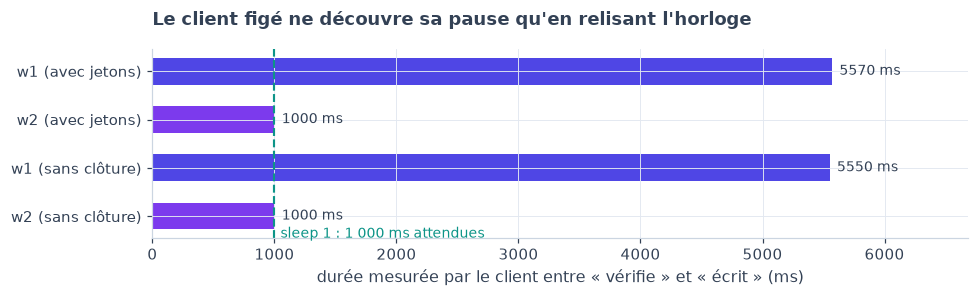

,client,scénario,durée_mesurée_ms
0,w2,sans clôture,1000
1,w1,sans clôture,5550
2,w2,avec jetons,1000
3,w1,avec jetons,5570


In [6]:
duree = pd.DataFrame([
    dict(client=r.client, scénario=nom, durée_mesurée_ms=int(r.valeur))
    for nom, ev in [("sans clôture", ev_naif), ("avec jetons", ev_jet)]
    for _, r in ev[ev.événement.str.startswith("ecriture")].iterrows()])
fig, ax = plt.subplots(figsize=(9, 2.8))
lab = [f"{r.client} ({r.scénario})" for r in duree.itertuples()]
ax.barh(lab, duree.durée_mesurée_ms, color=[INDIGO if c == "w1" else VIOLET for c in duree.client], height=0.55)
ax.axvline(1000, color=TEAL, ls="--", lw=1.4); ax.text(1050, -0.45, "sleep 1 : 1 000 ms attendues", color=TEAL, fontsize=9)
for y, v in enumerate(duree.durée_mesurée_ms):
    ax.text(v + 60, y, f"{v} ms", va="center", fontsize=9)
ax.set_xlabel("durée mesurée par le client entre « vérifie » et « écrit » (ms)")
ax.set_xlim(0, duree.durée_mesurée_ms.max() * 1.2)
ax.set_title("Le client figé ne découvre sa pause qu'en relisant l'horloge")
plt.tight_layout(); plt.show()
duree

Pour `worker2`, la « seconde » a duré une seconde ; pour `worker1`, plus de cinq : il
a dormi pendant toute la durée du gel. Il pourrait le constater en comparant ses lectures
d'horloge, mais **après coup** seulement, et rien ne garantit qu'une nouvelle pause ne
surviendra pas entre cette vérification et l'écriture suivante. D'où la conclusion du
livre : la sécurité doit être assurée par la ressource protégée, pas par le client.

## 5. Pour aller plus loin, et arrêt des services

- **Le service de verrous lui-même** est ici un Redis unique : s'il tombe, plus de verrou ;
  s'il est répliqué de façon asynchrone et qu'un réplica en retard est promu, un bail peut
  être accordé deux fois. Un service de verrous sérieux repose sur un algorithme de
  consensus (ZooKeeper, etcd), comme le verra le chapitre 10 ; et même
  alors, seuls les jetons de clôture protègent des pauses des clients. C'est le cœur du
  débat public de 2016 entre Martin Kleppmann et l'auteur de Redis autour de l'algorithme
  Redlock.
- **Variante à essayer** : remplacer le gel par un retard réseau (`docker network
  disconnect` puis `connect` sur `worker1` entre la vérification et l'écriture) ; ou faire
  redémarrer le service de verrous (`docker restart ddia_distsys-lock-1`) : son compteur de
  jetons, en mémoire, repart de zéro, et le stockage refuse alors **tous** les nouveaux
  jetons, que se passe-t-il ensuite ? (Indice : le cours 5, section 5.)

Quand vous avez terminé :

In [7]:
ps = subprocess.run(["docker", "compose", "-f", "../../docker/distsys/compose.yml", "-p", PROJET, "ps",
                     "--format", "{{.Name}} {{.State}}"], capture_output=True, text=True)
print(ps.stdout)
# Pour arrêter et supprimer les conteneurs (décommentez) :
# subprocess.run(["docker", "compose", "-f", "../../docker/distsys/compose.yml", "-p", PROJET, "down", "-v"], check=True)

ddia_distsys-lock-1 running
ddia_distsys-storage-1 running
ddia_distsys-worker1-1 running
ddia_distsys-worker2-1 running



## Synthèse

- Un verrou à bail Redis (`SET NX PX`) est exclusif tant que le serveur ne l'a pas fait
  expirer, sans rien savoir de l'état réel du détenteur.
- Une pause du client (ici `docker pause`) entre la vérification du bail et l'écriture
  suffit à produire une écriture de zombie qui écrase celle du détenteur légitime.
- Des **jetons de clôture** attribués avec le bail et vérifiés atomiquement par le stockage
  rendent le zombie inoffensif ; le client ne découvre sa pause qu'après coup.

Liens : cours 4 de ce chapitre (simulation du même scénario) ; services de verrous et
consensus au chapitre 10.